Imports

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

Load Dataset

In [2]:
# change path to your dataset
df = pd.read_csv("bihar_flood_data.csv")

df.head()

,Date,District,Rainfall_mm,River_Level_m,Danger_Level_m,Flood,Population,Crop_Area_ha
0,2023-11-27,Araria,101.86,5.45,12.0,0,2794130,45827
1,2016-05-25,Purnia,67.95,5.67,12.0,0,1522966,57670
2,2016-01-05,Supaul,62.59,4.82,12.0,0,2428881,90847
3,2017-04-27,Begusarai,46.94,4.81,12.0,0,1743325,88113
4,2022-12-18,Jamui,48.06,4.69,12.0,0,2017991,52990


Basic Inspection

In [3]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5600 entries, 0 to 5599
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            5600 non-null   object 
 1   District        5600 non-null   object 
 2   Rainfall_mm     5600 non-null   float64
 3   River_Level_m   5600 non-null   float64
 4   Danger_Level_m  5600 non-null   float64
 5   Flood           5600 non-null   int64  
 6   Population      5600 non-null   int64  
 7   Crop_Area_ha    5600 non-null   int64  
dtypes: float64(3), int64(3), object(2)
memory usage: 350.1+ KB


Date              0
District          0
Rainfall_mm       0
River_Level_m     0
Danger_Level_m    0
Flood             0
Population        0
Crop_Area_ha      0
dtype: int64

In [7]:
df = df.dropna()

Define Features and Target

In [4]:
# Example:
target_column = "Flood"   # change this

X = df.drop(columns=[target_column])
y = df[target_column]

Train-Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)

Handle Non-Numeric Data FIRST

In [9]:
# Convert date column if exists
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    
    # Extract useful features
    df['year'] = df['Date'].dt.year
    df['month'] = df['Date'].dt.month
    df['day'] = df['Date'].dt.day
    
    # Drop original date column
    df = df.drop(columns=['Date'])

Encode Categorical Columns

In [10]:
# Convert categorical columns to numeric
df = pd.get_dummies(df, drop_first=True)

Re-define X and y AGAIN

In [11]:
target_column = "Flood"  # same as before

X = df.drop(columns=[target_column])
y = df[target_column]

Train-Test Split

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Train RF (same)

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Predictions

In [15]:
y_pred = rf_model.predict(X_test)

Accuracy & F1 Score

In [16]:
from sklearn.metrics import accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("F1 Score:", f1)

Accuracy: 0.9392857142857143
F1 Score: 0.8162162162162162


Detailed Report

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.98      0.96       921
           1       0.88      0.76      0.82       199

    accuracy                           0.94      1120
   macro avg       0.92      0.87      0.89      1120
weighted avg       0.94      0.94      0.94      1120



Confusion Matrix

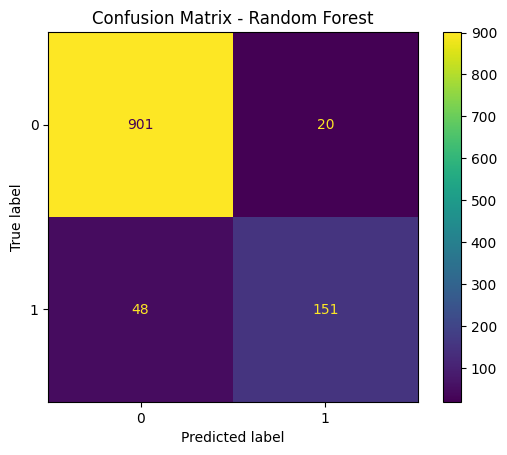

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test)
plt.title("Confusion Matrix - Random Forest")
plt.show()

Feature Importance

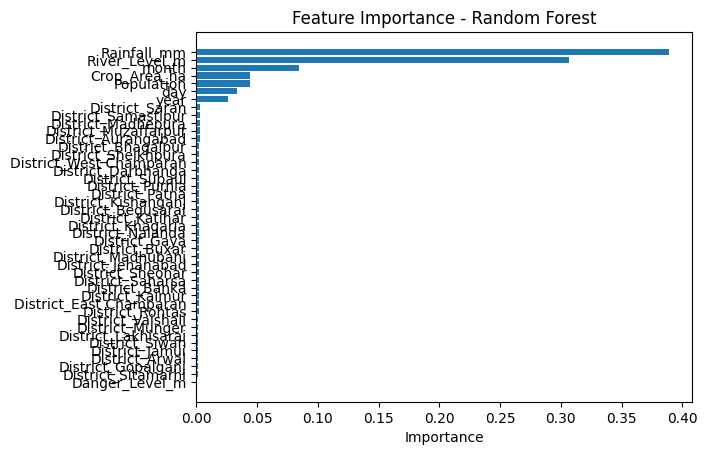

In [21]:
import numpy as np

importances = rf_model.feature_importances_
features = X.columns

# Sort for better visualization
indices = np.argsort(importances)

plt.figure()
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel("Importance")
plt.title("Feature Importance - Random Forest")
plt.show()

ROC Curve

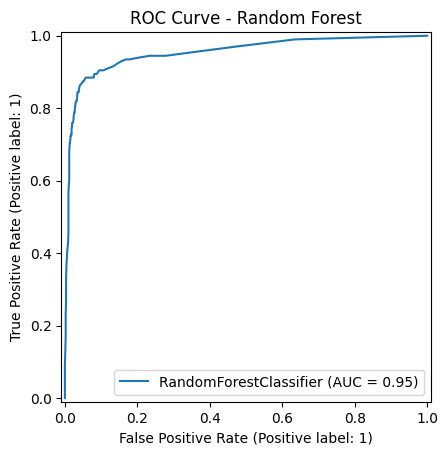

In [22]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(rf_model, X_test, y_test)
plt.title("ROC Curve - Random Forest")
plt.show()

Precision-Recall Curve

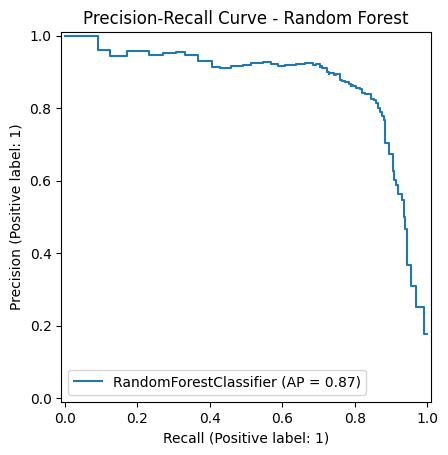

In [23]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(rf_model, X_test, y_test)
plt.title("Precision-Recall Curve - Random Forest")
plt.show()

Prediction Distribution

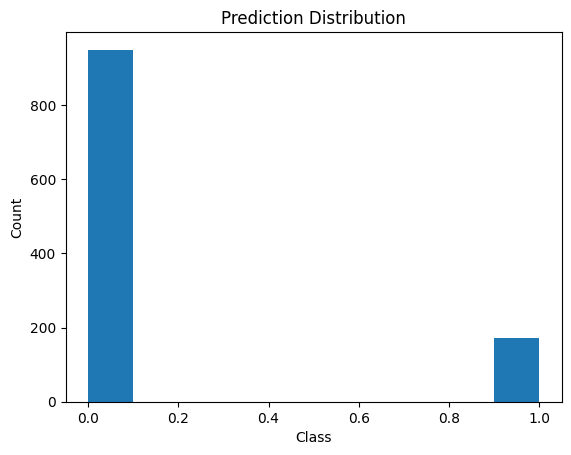

In [24]:
plt.hist(y_pred)
plt.title("Prediction Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()